# Grammar Scoring Engine for Spoken Audio (v5 - simpler, leak-free, fast)

**Task:** predict a grammar score (0-5) from a 45-60 s clip. Metrics: RMSE (lower is better) and Pearson.

## What changed from v4 and why
| v4 problem | v5 fix |
|---|---|
| Layer selection used the **validation-fold labels** (optimistic CV), and the final fit picked layers by *in-sample* error (a different rule than CV) | No label-based layer picking. Each view uses a fixed band of layers; 3 candidate bands are compared by CV (3 options only) |
| PLS with a fixed 20 components, Ridge with a fixed alpha | **Kernel ridge** with alpha chosen **per fold** by an exact leave-one-out formula (training fold only, no leakage, almost free) |
| Every CV fold re-built huge feature matrices (up to 51k columns) | Features become **985 x 985 kernels once**; every CV fold is just an index slice -> CV takes seconds and memory stays small |
| No non-linear model on audio | Adds an **RBF-SVR** on the combined kernel of all four views |
| Models loaded even when cached, duplicated cell 4b, dead commented code | Models load only if a cache is missing; one clean pipeline |

**Models (7 base learners -> non-negative linear stacker):** one kernel-ridge per audio view (WavLM-base, Whisper-small enc, WavLM-large, Whisper-medium enc), kernel-ridge and RBF-SVR on the sum of all four view kernels, and a small LightGBM on the 63 grammar/fluency features.

**Why not XGBoost?** Trees are the right tool for the 63 tabular grammar features (LightGBM is used there; XGBoost would give the same result). On thousands of dense embedding columns with only 769 clips, trees lose clearly to linear/kernel models (your own v4 log: GBM 0.74 vs 0.53-0.60 for the embedding models).

**Runtime:** with the feature caches in `./working/cache` (same file names as v3/v4) the whole notebook runs in about a minute on CPU. Without caches, feature extraction needs a GPU (about 30-40 min on a T4).

In [1]:
!pip install -q openai-whisper language-tool-python lightgbm kagglehub

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 803.2/803.2 kB 11.2 MB/s eta 0:00:0000:0100:01
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 63.2/63.2 kB 2.4 MB/s eta 0:00:00


In [2]:
import os, re, json, gc, math, time, warnings, random
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
import librosa
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
from scipy.stats import pearsonr

from sklearn.model_selection import StratifiedKFold, KFold
from sklearn.linear_model import LinearRegression
from sklearn.svm import SVR
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from lightgbm import LGBMRegressor

warnings.filterwarnings("ignore")
SEED = 42
np.random.seed(SEED); random.seed(SEED); torch.manual_seed(SEED)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", DEVICE)

# ---------------- configuration ----------------
WHISPER_MODEL = "small"                     # used for ASR and as audio view 2
WAVLM_NAME = "microsoft/wavlm-base-plus"    # audio view 1
USE_EXTRA_VIEWS = True                      # audio views 3 and 4 (WavLM-large, Whisper-medium encoder)
WAVLM_LARGE = "microsoft/wavlm-large"
WHISPER_ENC_BIG = "medium"
DATA_ROOT = None                            # folder containing train.csv if not on Kaggle
MAX_SEC, SR = 60, 16000

WORK = Path("./working"); CACHE = WORK / "cache"     # keep the v3/v4 cache folder to skip extraction
CACHE.mkdir(parents=True, exist_ok=True)

def rmse(y_true, y_pred):
    return float(np.sqrt(mean_squared_error(y_true, y_pred)))

def free_gpu():
    gc.collect()
    if DEVICE == "cuda":
        torch.cuda.empty_cache()

Device: cuda


## 1. Load data

In [3]:
if DATA_ROOT is None:
    try:
        import kagglehub
        DATA_ROOT = kagglehub.competition_download("shl-hiring-assessment-2026")
    except Exception as e:
        print("kagglehub failed:", repr(e)[:120])
        DATA_ROOT = "/kaggle/input"
train_csv = next(Path(DATA_ROOT).rglob("train.csv"))
DATA_DIR = train_csv.parent

train_df = pd.read_csv(DATA_DIR / "train.csv")
test_df = pd.read_csv(DATA_DIR / "test.csv")
sample_sub = pd.read_csv(DATA_DIR / "sample_submission.csv")

train_lookup = {p.name: p for p in (DATA_DIR / "train").rglob("*.wav")}
test_lookup = {p.name: p for p in (DATA_DIR / "test").rglob("*.wav")}
train_df["audio_path"] = train_df["filename"].map(train_lookup)
test_df["audio_path"] = test_df["filename"].map(test_lookup)
assert train_df["audio_path"].notna().all() and test_df["audio_path"].notna().all()

# One combined table so each (unsupervised) feature extractor runs once. No labels are used for features.
all_df = pd.concat([train_df.assign(split="train"), test_df.assign(split="test")], ignore_index=True)
N_TRAIN, N_ALL = len(train_df), len(all_df)
y = train_df["label"].astype(float).values
print("Train:", N_TRAIN, "| Test:", len(test_df), "| predict-mean RMSE: %.3f" % y.std())

def load_audio(p):
    a, _ = librosa.load(str(p), sr=SR, mono=True)
    a = a[: SR * MAX_SEC]
    if len(a) < SR:                                   # very short clip: pad to 1 s so models do not crash
        a = np.pad(a, (0, SR - len(a)))
    return a.astype(np.float32)

Train: 769 | Test: 216 | predict-mean RMSE: 1.238


## 2. Whisper transcription (cached, resumable)
Gives the transcript (for grammar checks) and per-word probabilities/timings (unclear speech lowers Whisper's confidence).

In [4]:
import whisper

def transcribe_one(model, path):
    try:
        r = model.transcribe(load_audio(path), language="en", fp16=(DEVICE == "cuda"),
                             word_timestamps=True, condition_on_previous_text=False)
    except Exception as e:
        print("ASR error:", path, repr(e)[:100])
        return {"text": "", "segments": [], "words": []}
    segs, words = [], []
    for s in r["segments"]:
        segs.append({k: float(s[k]) for k in ("avg_logprob", "no_speech_prob", "compression_ratio")})
        for w in s.get("words", []):
            words.append({"word": w["word"], "start": float(w["start"]),
                          "end": float(w["end"]), "probability": float(w["probability"])})
    return {"text": r["text"].strip(), "segments": segs, "words": words}

def transcribe_all(df):
    cache_f = CACHE / f"asr_{WHISPER_MODEL}.json"
    out = json.load(open(cache_f)) if cache_f.exists() else {}
    todo = [(n, p) for n, p in zip(df["filename"], df["audio_path"]) if n not in out]
    if todo:                                          # load the model only if something is missing
        model = whisper.load_model(WHISPER_MODEL, device=DEVICE)
        for i, (n, p) in enumerate(tqdm(todo, desc="Transcribing")):
            out[n] = transcribe_one(model, p)
            if (i + 1) % 100 == 0:
                json.dump(out, open(cache_f, "w"))
        json.dump(out, open(cache_f, "w"))
        del model; free_gpu()
    return out

asr = transcribe_all(all_df)
all_df["transcript"] = all_df["filename"].map(lambda n: asr[n]["text"])
print("Empty transcripts:", int((all_df["transcript"].str.strip() == "").sum()))

100%|████████████████████████████████████████| 461M/461M [00:02<00:00, 207MiB/s]


Transcribing:   0%|          | 0/985 [00:00<?, ?it/s]

Empty transcripts: 10


## 3. Audio embeddings - four views (the strongest signal)
For every clip and **every layer** of each speech model we keep the mean and std of the hidden states over time (Whisper: only real, unpadded frames of each 30 s window). Pooling is accumulated on the fly, so memory stays flat. Everything is cached to disk; models are loaded only when their cache is missing and freed right after use.

In [5]:
from transformers import AutoFeatureExtractor, AutoModel

CHUNK = 30 * SR      # Whisper encoder window = 30 s

def pool_hidden(hs):
    mean = torch.stack([h[0].float().mean(0) for h in hs]).cpu().numpy()
    std = torch.stack([h[0].float().std(0) for h in hs]).cpu().numpy()
    return mean, std

@torch.no_grad()
def wavlm_pooled(model, feat_ext, a):
    x = feat_ext(a, sampling_rate=SR, return_tensors="pt").input_values.to(DEVICE)
    with torch.autocast(device_type="cuda", enabled=(DEVICE == "cuda")):
        hs = model(x, output_hidden_states=True).hidden_states
    m, s = pool_hidden(hs)
    if not (np.isfinite(m).all() and np.isfinite(s).all()):     # fp16 safety net: redo this clip in fp32
        hs = model(x, output_hidden_states=True).hidden_states
        m, s = pool_hidden(hs)
    return m, s

@torch.no_grad()
def whisper_enc_pooled(enc, store, a, n_mels):
    L = len(enc.blocks); D = enc.ln_post.weight.shape[0]
    s1 = torch.zeros(L, D, device=DEVICE); s2 = torch.zeros(L, D, device=DEVICE); n = 0
    for start in range(0, len(a), CHUNK):
        chunk = a[start:start + CHUNK]
        if start > 0 and len(chunk) < 2 * SR:                   # ignore a tiny tail
            break
        mel = whisper.log_mel_spectrogram(whisper.pad_or_trim(chunk), n_mels=n_mels).to(DEVICE)[None]
        valid = min(1500, math.ceil(len(chunk) / 320))          # 1 encoder frame = 20 ms = 320 samples
        store.clear()
        with torch.autocast(device_type="cuda", enabled=(DEVICE == "cuda")):
            enc(mel)
        H = torch.stack([o[0, :valid].float() for o in store])
        s1 += H.sum(1); s2 += (H ** 2).sum(1); n += valid
        del H
    mean = s1 / n
    return mean.cpu().numpy(), (s2 / n - mean ** 2).clamp_min(0).sqrt().cpu().numpy()

def run_wavlm(name):
    fe = AutoFeatureExtractor.from_pretrained(name)
    model = AutoModel.from_pretrained(name).to(DEVICE).eval()
    ms, ss = [], []
    for p in tqdm(all_df["audio_path"], desc=name.split("/")[-1]):
        m, s = wavlm_pooled(model, fe, load_audio(p)); ms.append(m); ss.append(s)
    del model, fe; free_gpu()
    return np.stack(ms).astype(np.float32), np.stack(ss).astype(np.float32)

def run_whisper_enc(size):
    wm = whisper.load_model(size, device=DEVICE)
    enc = wm.encoder.eval(); n_mels = wm.dims.n_mels
    store = []
    hooks = [b.register_forward_hook(lambda m_, i_, o_: store.append(o_)) for b in enc.blocks]
    ms, ss = [], []
    for p in tqdm(all_df["audio_path"], desc=f"Whisper-{size} encoder"):
        m, s = whisper_enc_pooled(enc, store, load_audio(p), n_mels); ms.append(m); ss.append(s)
    for h in hooks: h.remove()
    del wm, enc, store; free_gpu()
    return np.stack(ms).astype(np.float32), np.stack(ss).astype(np.float32)

def signal_stats(a):
    rms = librosa.feature.rms(y=a)[0]
    iv = librosa.effects.split(a, top_db=30)
    return {"duration": len(a) / SR, "rms_mean": rms.mean(), "rms_std": rms.std(),
            "voiced_ratio": (sum(e - s for s, e in iv) / len(a)) if len(iv) else 0.0,
            "n_voiced_segments": len(iv)}

# ---- views 1 and 2 (+ basic signal stats): same cache file/format as v3/v4 ----
A_cache = CACHE / f"audio_{WHISPER_MODEL}_{WAVLM_NAME.split('/')[-1]}.pkl"
if A_cache.exists():
    A = pd.read_pickle(A_cache)
else:
    sig = [signal_stats(load_audio(p)) for p in tqdm(all_df["audio_path"], desc="Signal stats")]
    wm_, ws_ = run_wavlm(WAVLM_NAME)
    hm_, hs_ = run_whisper_enc(WHISPER_MODEL)
    A = dict(sig=pd.DataFrame(sig), wavlm_mean=wm_, wavlm_std=ws_, whis_mean=hm_, whis_std=hs_)
    pd.to_pickle(A, A_cache)
audio_feat_df = A["sig"]

VIEWS = {"WavLM-base": (A["wavlm_mean"], A["wavlm_std"]),
         "Whisper-small enc": (A["whis_mean"], A["whis_std"])}

# ---- views 3 and 4: same cache file/format as v4; a partial cache is resumed ----
if USE_EXTRA_VIEWS:
    extra_cache = CACHE / f"extra_{WAVLM_LARGE.split('/')[-1]}_{WHISPER_ENC_BIG}.pkl"
    EXTRA = pd.read_pickle(extra_cache) if extra_cache.exists() else {}
    for key, fn in [("WavLM-large", lambda: run_wavlm(WAVLM_LARGE)),
                    (f"Whisper-{WHISPER_ENC_BIG} enc", lambda: run_whisper_enc(WHISPER_ENC_BIG))]:
        if key not in EXTRA:
            EXTRA[key] = fn(); pd.to_pickle(EXTRA, extra_cache)
    VIEWS.update(EXTRA)
print({k: v[0].shape for k, v in VIEWS.items()})

Signal stats:   0%|          | 0/985 [00:00<?, ?it/s]

preprocessor_config.json:   0%|          | 0.00/215 [00:00<?, ?B/s]

config.json: 0.00B [00:00, ?B/s]

pytorch_model.bin:   0%|          | 0.00/378M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/248 [00:00<?, ?it/s]

...

model.safetensors:   0%|          | 0.00/1.26G [00:00<?, ?B/s]

wavlm-large:   0%|          | 0/985 [00:00<?, ?it/s]

100%|█████████████████████████████████████| 1.42G/1.42G [00:23<00:00, 65.8MiB/s]


Whisper-medium encoder:   0%|          | 0/985 [00:00<?, ?it/s]

{'WavLM-base': (985, 13, 768), 'Whisper-small enc': (985, 12, 768), 'WavLM-large': (985, 25, 1024), 'Whisper-medium enc': (985, 24, 1024)}


## 4. Hand-crafted grammar and fluency features (from the transcript)
Interpretable evidence that raw embeddings do not expose directly: Whisper confidence and pauses, text statistics, LanguageTool error rates, GPT-2 fluency, CoLA grammatical acceptability (63 features in total).

In [6]:
# ---- 4a. Whisper confidence and timing ----
ASR_KEYS = ["asr_n_words", "asr_wps", "asr_n_segs", "asr_lp_mean", "asr_lp_min", "asr_lp_std",
            "asr_nospeech_mean", "asr_nospeech_max", "asr_compr_mean", "asr_compr_max",
            "wp_mean", "wp_std", "wp_min", "wp_p25", "wp_frac_lt50", "wp_frac_lt80",
            "pause_mean", "pause_std", "pause_max", "pause_frac_gt025", "pause_n_gt1",
            "pause_ratio", "lead_silence", "trail_silence", "artic_rate"]

def asr_feats(rec, dur):
    f = {k: np.nan for k in ASR_KEYS}
    words, segs = rec["words"], rec["segments"]
    n = len(words)
    f["asr_n_words"] = n; f["asr_wps"] = n / max(dur, 1e-6); f["asr_n_segs"] = len(segs)
    if segs:
        lp = np.array([s["avg_logprob"] for s in segs]); ns = np.array([s["no_speech_prob"] for s in segs])
        cr = np.array([s["compression_ratio"] for s in segs])
        f.update(asr_lp_mean=lp.mean(), asr_lp_min=lp.min(), asr_lp_std=lp.std(),
                 asr_nospeech_mean=ns.mean(), asr_nospeech_max=ns.max(),
                 asr_compr_mean=cr.mean(), asr_compr_max=cr.max())
    if n >= 2:
        p = np.array([w["probability"] for w in words])
        st = np.array([w["start"] for w in words]); en = np.array([w["end"] for w in words])
        gaps = np.maximum(st[1:] - en[:-1], 0); span = max(en[-1] - st[0], 1e-6)
        f.update(wp_mean=p.mean(), wp_std=p.std(), wp_min=p.min(), wp_p25=np.percentile(p, 25),
                 wp_frac_lt50=(p < 0.5).mean(), wp_frac_lt80=(p < 0.8).mean(),
                 pause_mean=gaps.mean(), pause_std=gaps.std(), pause_max=gaps.max(),
                 pause_frac_gt025=(gaps > 0.25).mean(), pause_n_gt1=(gaps > 1.0).sum(),
                 pause_ratio=gaps.sum() / span, lead_silence=st[0],
                 trail_silence=max(dur - en[-1], 0), artic_rate=n / span)
    return f

asr_feat_df = pd.DataFrame([asr_feats(asr[n], d) for n, d in zip(all_df["filename"], audio_feat_df["duration"])])

# ---- 4b. Surface text statistics ----
FILLERS = {"um", "uh", "er", "erm", "hmm", "mm", "ah"}
CONNECT = {"and", "but", "because", "although", "which", "that", "while", "if", "when", "so", "however", "since", "though"}
TEXT_KEYS = ["n_words", "n_unique", "ttr", "root_ttr", "avg_word_len", "long_word_ratio", "n_sents",
             "avg_sent_len", "max_sent_len", "std_sent_len", "short_sent_ratio", "long_sent_ratio",
             "imm_repeat_ratio", "bigram_repeat_ratio", "filler_ratio", "connective_ratio",
             "i_ratio", "contraction_ratio"]

def text_feats(text):
    f = {k: 0.0 for k in TEXT_KEYS}
    text = (text or "").strip()
    words = re.findall(r"[a-zA-Z']+", text.lower()); n = len(words)
    if n == 0:
        return f
    sents = [s for s in re.split(r"[.!?]+", text) if s.strip()]
    sl = np.array([len(re.findall(r"[a-zA-Z']+", s)) for s in sents]) if sents else np.array([n])
    bigrams = list(zip(words[:-1], words[1:]))
    f.update(n_words=n, n_unique=len(set(words)), ttr=len(set(words)) / n, root_ttr=len(set(words)) / np.sqrt(n),
             avg_word_len=np.mean([len(w) for w in words]), long_word_ratio=np.mean([len(w) >= 7 for w in words]),
             n_sents=len(sl), avg_sent_len=sl.mean(), max_sent_len=sl.max(), std_sent_len=sl.std(),
             short_sent_ratio=(sl <= 3).mean(), long_sent_ratio=(sl >= 25).mean(),
             imm_repeat_ratio=np.mean([a == b for a, b in bigrams]) if bigrams else 0,
             bigram_repeat_ratio=1 - len(set(bigrams)) / max(len(bigrams), 1),
             filler_ratio=np.mean([w in FILLERS for w in words]), connective_ratio=np.mean([w in CONNECT for w in words]),
             i_ratio=np.mean([w == "i" for w in words]), contraction_ratio=np.mean(["'" in w for w in words]))
    return f

text_feat_df = pd.DataFrame([text_feats(t) for t in all_df["transcript"]])
print("ASR feats:", asr_feat_df.shape, "| text feats:", text_feat_df.shape)

ASR feats: (985, 25) | text feats: (985, 18)


In [7]:
# ---- 4c. LanguageTool grammar errors per 100 words (skipped automatically if Java is unavailable) ----
LT_KEYS = ["lt_total_per100", "lt_grammar_per100", "lt_typos_per100", "lt_agree_per100", "lt_other_per100"]
lt_cache = CACHE / f"lt_{WHISPER_MODEL}.pkl"

def compute_lt(texts):
    import language_tool_python
    tool = language_tool_python.LanguageTool("en-US")
    ignore = {"CASING", "PUNCTUATION", "TYPOGRAPHY", "WHITESPACE"}   # Whisper artifacts, not speaker mistakes
    rows = []
    for t in tqdm(texts, desc="LanguageTool"):
        try:
            n = max(len(re.findall(r"[A-Za-z']+", t)), 1)
            ms = tool.check(t) if t.strip() else []
            cat = [(getattr(m, "category", "") or "").upper() for m in ms]
            rid = [(getattr(m, "ruleId", "") or "").upper() for m in ms]
            keep = [i for i, c in enumerate(cat) if c not in ignore]
            n_gram = sum(cat[i] == "GRAMMAR" for i in keep); n_typo = sum(cat[i] == "TYPOS" for i in keep)
            n_agree = sum(any(k in rid[i] for k in ("AGR", "NON3PRS", "VERB", "VBZ", "PRP_", "TENSE")) for i in keep)
            rows.append({"lt_total_per100": 100 * len(keep) / n, "lt_grammar_per100": 100 * n_gram / n,
                         "lt_typos_per100": 100 * n_typo / n, "lt_agree_per100": 100 * n_agree / n,
                         "lt_other_per100": 100 * (len(keep) - n_gram - n_typo) / n})
        except Exception:
            rows.append({k: np.nan for k in LT_KEYS})
    tool.close()
    return pd.DataFrame(rows)

try:
    if lt_cache.exists():
        lt_feat_df = pd.read_pickle(lt_cache)
    else:
        lt_feat_df = compute_lt(all_df["transcript"].tolist()); lt_feat_df.to_pickle(lt_cache)
    print("LanguageTool features:", lt_feat_df.shape)
except Exception as e:
    print("LanguageTool unavailable, skipping:", repr(e)[:150])
    lt_feat_df = pd.DataFrame(index=range(len(all_df)))

LanguageTool:   0%|          | 0/985 [00:00<?, ?it/s]

LanguageTool features: (985, 5)


In [8]:
# ---- 4d. GPT-2 fluency (low "surprise" = natural word sequence) and 4e. CoLA grammatical acceptability ----
from transformers import AutoTokenizer, AutoModelForCausalLM, AutoModelForSequenceClassification
lm_cache = CACHE / f"lm_cola_{WHISPER_MODEL}.pkl"
LM_KEYS = ["lm_nll_mean", "lm_nll_median", "lm_nll_p90", "lm_nll_std"]
COLA_KEYS = ["cola_mean", "cola_min", "cola_median", "cola_std", "cola_frac_ok", "cola_n_sents"]

if lm_cache.exists():
    lm_feat_df, cola_feat_df = pd.read_pickle(lm_cache)
else:
    gpt_tok = AutoTokenizer.from_pretrained("gpt2")
    gpt = AutoModelForCausalLM.from_pretrained("gpt2").to(DEVICE).eval()

    @torch.no_grad()
    def lm_feats(text):
        f = {k: np.nan for k in LM_KEYS}
        ids = gpt_tok(text or "", return_tensors="pt", truncation=True, max_length=1000).input_ids
        if ids.shape[1] < 2:
            return f
        ids = torch.cat([torch.tensor([[gpt_tok.bos_token_id]]), ids], dim=1).to(DEVICE)
        nll = F.cross_entropy(gpt(ids).logits[0, :-1], ids[0, 1:], reduction="none").cpu().numpy()
        f.update(lm_nll_mean=nll.mean(), lm_nll_median=np.median(nll), lm_nll_p90=np.percentile(nll, 90), lm_nll_std=nll.std())
        return f

    lm_feat_df = pd.DataFrame([lm_feats(t) for t in tqdm(all_df["transcript"], desc="GPT-2 fluency")])
    del gpt; free_gpu()

    try:
        cola_tok = AutoTokenizer.from_pretrained("textattack/roberta-base-CoLA")
        cola = AutoModelForSequenceClassification.from_pretrained("textattack/roberta-base-CoLA").to(DEVICE).eval()

        @torch.no_grad()
        def cola_feats(text):
            f = {k: np.nan for k in COLA_KEYS}
            sents = [s.strip() for s in re.split(r"(?<=[.!?])\s+", (text or "").strip()) if len(s.split()) >= 2]
            if not sents:
                return f
            probs = []
            for i in range(0, len(sents), 16):
                enc = cola_tok(sents[i:i + 16], return_tensors="pt", padding=True, truncation=True, max_length=96).to(DEVICE)
                probs.extend(F.softmax(cola(**enc).logits, dim=-1)[:, 1].cpu().numpy().tolist())
            p = np.array(probs)
            f.update(cola_mean=p.mean(), cola_min=p.min(), cola_median=np.median(p), cola_std=p.std(),
                     cola_frac_ok=(p > 0.5).mean(), cola_n_sents=len(p))
            return f

        cola_feat_df = pd.DataFrame([cola_feats(t) for t in tqdm(all_df["transcript"], desc="CoLA acceptability")])
        del cola; free_gpu()
    except Exception as e:
        print("CoLA model unavailable, skipping:", repr(e)[:150])
        cola_feat_df = pd.DataFrame(index=range(len(all_df)))
    pd.to_pickle((lm_feat_df, cola_feat_df), lm_cache)

hand_df = pd.concat([audio_feat_df, asr_feat_df, text_feat_df, lt_feat_df, lm_feat_df, cola_feat_df], axis=1)
hand_df = hand_df.replace([np.inf, -np.inf], np.nan)
X_hand_all = hand_df.values.astype(np.float32)           # LightGBM handles NaN natively
print("Hand-crafted features:", hand_df.shape[1])

config.json:   0%|          | 0.00/665 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

...

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

RobertaForSequenceClassification LOAD REPORT from: textattack/roberta-base-CoLA
Key                         | Status     |  | 
----------------------------+------------+--+-
roberta.pooler.dense.weight | UNEXPECTED |  | 
roberta.pooler.dense.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


model.safetensors:   0%|          | 0.00/501M [00:00<?, ?B/s]

CoLA acceptability:   0%|          | 0/985 [00:00<?, ?it/s]

Hand-crafted features: 63


## 5. Turn each audio view into a small kernel matrix
Each layer's `[mean, std]` features are z-scored (using all 985 clips, **no labels involved**) and turned into a 985 x 985 linear kernel. After this the big embedding arrays are deleted, so memory drops from ~0.5 GB to a few MB per view.

**Which layers?** Low layers mostly encode acoustics, upper layers carry phonetic/lexical content that grammar depends on. Instead of picking single layers by label (the v4 leak), each view averages the kernels of a *band* of layers, and three fixed bands are compared by CV (only 3 options per view, so selection bias is negligible).

In [9]:
def layer_kernels(mean_emb, std_emb):
    """(L, n, n) linear kernels, one per layer, from z-scored [mean, std] pooled features."""
    L, n = mean_emb.shape[1], mean_emb.shape[0]
    K = np.empty((L, n, n), dtype=np.float32)
    for l in range(L):
        Z = np.nan_to_num(np.concatenate([mean_emb[:, l], std_emb[:, l]], axis=1).astype(np.float32))
        Z = (Z - Z.mean(0)) / (Z.std(0) + 1e-6)
        K[l] = (Z @ Z.T) / Z.shape[1]
    return K

def make_bins(yv):
    return np.digitize(yv, [0.5, 2.25, 3.25, 4.25, 4.75])
BINS = make_bins(y)

def cv_oof(fn, n_repeats=3, n_splits=5):
    """Out-of-fold predictions. fn(train_idx, eval_idx) -> predictions for eval_idx (indices into all_df)."""
    oof = np.zeros((n_repeats, N_TRAIN))
    for r in range(n_repeats):
        skf = StratifiedKFold(n_splits, shuffle=True, random_state=SEED + r)
        for tr, va in skf.split(np.zeros(N_TRAIN), BINS):
            oof[r, va] = fn(tr, va)
    return np.clip(oof.mean(0), 0, 5)

ALPHAS = np.logspace(-3, 3, 25)       # relative to the kernel scale (mean diagonal ~ 1)

def krr(K, tr, te):
    """Kernel ridge with intercept. Alpha is chosen on the training fold only, by the exact leave-one-out error."""
    Ktr = K[np.ix_(tr, tr)].astype(np.float64)
    Kte = K[np.ix_(te, tr)].astype(np.float64)
    cm = Ktr.mean(0); tm = cm.mean()
    Kc = Ktr - cm[None, :] - cm[:, None] + tm                        # centre the kernel (intercept)
    Kte_c = Kte - Kte.mean(1, keepdims=True) - cm[None, :] + tm
    ym = y[tr].mean(); yc = y[tr] - ym
    s, U = np.linalg.eigh(Kc); s = np.clip(s, 0, None)
    Uty = U.T @ yc; U2 = U ** 2
    best_a, best_e = ALPHAS[0], np.inf
    for a in ALPHAS:
        shrink = s / (s + a)
        loo = (yc - U @ (shrink * Uty)) / np.maximum(1 - 1 / len(tr) - U2 @ shrink, 1e-6)   # exact LOO incl. intercept
        e = np.mean(loo ** 2)
        if e < best_e:
            best_a, best_e = a, e
    return Kte_c @ (U @ (Uty / (s + best_a))) + ym

krr_fn = lambda K: (lambda tr, te: krr(K, tr, te))

BANDS = {"all layers": 0.0, "upper 2/3": 0.33, "upper half": 0.5}
VIEW_K = {}
for name, (mn, sd) in VIEWS.items():
    t0 = time.time()
    LK = layer_kernels(mn, sd); L = len(LK)
    scores = {}
    for b, frac in BANDS.items():
        K = LK[int(frac * L):].mean(0)
        scores[b] = (rmse(y, cv_oof(krr_fn(K), n_repeats=1)), K)
    best = min(scores, key=lambda b: scores[b][0])
    VIEW_K[name] = scores[best][1]
    print(f"{name:20s} " + " | ".join(f"{b}: {scores[b][0]:.4f}" for b in BANDS) + f"  -> {best} ({time.time()-t0:.0f}s)")
    del LK, scores
del VIEWS, A
if USE_EXTRA_VIEWS: del EXTRA
gc.collect()

WavLM-base           all layers: 0.5286 | upper 2/3: 0.5352 | upper half: 0.5335  -> all layers (1s)
Whisper-small enc    all layers: 0.5319 | upper 2/3: 0.5369 | upper half: 0.5521  -> all layers (2s)
WavLM-large          all layers: 0.5094 | upper 2/3: 0.5204 | upper half: 0.5264  -> all layers (2s)
Whisper-medium enc   all layers: 0.5184 | upper 2/3: 0.5321 | upper half: 0.5411  -> all layers (2s)


0

## 6. Base models, cross-validation and stacking
* **5-fold stratified CV, repeated 3 times.** Out-of-fold (OOF) RMSE is the honest estimate. All fold work is index slicing on precomputed kernels, so it is fast.
* Kernel ridge picks its own regularisation per fold (leave-one-out on the training part only). The RBF-SVR's `C` is compared on 3 values. LightGBM is small and strongly regularised.
* A **non-negative linear stacker** (few parameters, no shrinking tricks) learns how much to trust each base model from OOF predictions only.

In [10]:
K_all = np.mean(list(VIEW_K.values()), axis=0)                  # multi-view kernel: average of the view kernels
d = np.diag(K_all)
D2 = np.maximum(d[:, None] + d[None, :] - 2 * K_all, 0)
gamma = 1.0 / np.median(D2[np.triu_indices_from(D2, 1)])
K_rbf = np.exp(-gamma * D2)                                      # RBF kernel for the non-linear model

def svr_fn(C):
    def fn(tr, te):
        m = SVR(kernel="precomputed", C=C, epsilon=0.1)
        m.fit(K_rbf[np.ix_(tr, tr)], y[tr])
        return m.predict(K_rbf[np.ix_(te, tr)])
    return fn

best_C = min((1.0, 3.0, 10.0), key=lambda C: rmse(y, cv_oof(svr_fn(C), n_repeats=1)))
print("SVR C =", best_C)

def gbm_fn(tr, te):
    m = LGBMRegressor(n_estimators=400, learning_rate=0.02, num_leaves=8, min_child_samples=15, subsample=0.8,
                      subsample_freq=1, colsample_bytree=0.6, reg_lambda=5.0, random_state=SEED, verbose=-1, n_jobs=-1)
    m.fit(X_hand_all[tr], y[tr])
    return m.predict(X_hand_all[te])

models = {f"KRR {n}": krr_fn(K) for n, K in VIEW_K.items()}
models["KRR all views"] = krr_fn(K_all)
models["SVR-RBF all views"] = svr_fn(best_C)
models["LightGBM grammar feats"] = gbm_fn

oof = {}
for name, fn in models.items():
    t0 = time.time()
    oof[name] = cv_oof(fn)
    print(f"{name:26s} CV RMSE {rmse(y, oof[name]):.4f} | Pearson {pearsonr(y, oof[name])[0]:.3f} | {time.time()-t0:.0f}s")
names = list(oof)
oof_mat = np.column_stack([oof[n] for n in names])

SVR C = 3.0
KRR WavLM-base             CV RMSE 0.5154 | Pearson 0.910 | 1s
KRR Whisper-small enc      CV RMSE 0.5216 | Pearson 0.908 | 1s
KRR WavLM-large            CV RMSE 0.4913 | Pearson 0.918 | 1s
KRR Whisper-medium enc     CV RMSE 0.5003 | Pearson 0.915 | 1s
KRR all views              CV RMSE 0.4865 | Pearson 0.920 | 1s
SVR-RBF all views          CV RMSE 0.4896 | Pearson 0.920 | 0s
LightGBM grammar feats     CV RMSE 0.7427 | Pearson 0.800 | 4s


In [11]:
# ---- stacking: non-negative linear regression on OOF predictions ----
stacker = LinearRegression(positive=True).fit(oof_mat, y)
print("Stack weights:", {n: round(float(w), 3) for n, w in zip(names, stacker.coef_)}, "| intercept %.3f" % stacker.intercept_)

# honest estimate of the stacker itself: 5-fold CV on the OOF matrix, repeated 3 times
stack_runs = []
for r in range(3):
    p = np.zeros(N_TRAIN)
    for tr, va in KFold(5, shuffle=True, random_state=SEED + r).split(oof_mat):
        p[va] = LinearRegression(positive=True).fit(oof_mat[tr], y[tr]).predict(oof_mat[va])
    stack_runs.append(np.clip(p, 0, 5))
stack_cv = stack_runs[0]
cv_rmse_stack = float(np.mean([rmse(y, p) for p in stack_runs]))
cv_pearson = float(np.mean([pearsonr(y, p)[0] for p in stack_runs]))
cv_r2 = float(np.mean([r2_score(y, p) for p in stack_runs]))
cv_mae = float(np.mean([mean_absolute_error(y, p) for p in stack_runs]))

print(f"\nStacked CV RMSE   : {cv_rmse_stack:.4f}")
print(f"Stacked CV MAE    : {cv_mae:.4f}")
print(f"Stacked CV R2     : {cv_r2:.4f}")
print(f"Stacked CV Pearson: {cv_pearson:.4f}")
print(f"Baseline (predict mean) RMSE: {y.std():.4f}")

Stack weights: {'KRR WavLM-base': 0.018, 'KRR Whisper-small enc': 0.0, 'KRR WavLM-large': 0.304, 'KRR Whisper-medium enc': 0.229, 'KRR all views': 0.047, 'SVR-RBF all views': 0.397, 'LightGBM grammar feats': 0.081} | intercept -0.247

Stacked CV RMSE   : 0.4745
Stacked CV MAE    : 0.3462
Stacked CV R2     : 0.8531
Stacked CV Pearson: 0.9238
Baseline (predict mean) RMSE: 1.2382


## 7. Final fit on all 769 clips: training RMSE (required) and test predictions
Note: the stacker is fitted on *out-of-fold* predictions. In-sample base predictions are less shrunk than out-of-fold ones, so the stacked training RMSE is only a sanity number; it is **not** a generalisation measure. The CV RMSE is.

In [12]:
tr_idx, all_idx = np.arange(N_TRAIN), np.arange(N_ALL)
P = np.column_stack([np.clip(fn(tr_idx, all_idx), 0, 5) for fn in models.values()])   # one fit per model
train_stack = np.clip(stacker.predict(P[:N_TRAIN]), 0, 5)
test_stack = np.clip(stacker.predict(P[N_TRAIN:]), 0, 5)

TRAIN_RMSE = rmse(y, train_stack)
print("=" * 60)
print(f"TRAINING RMSE (in-sample, required)     : {TRAIN_RMSE:.4f}")
print(f"CROSS-VALIDATED RMSE (honest estimate)  : {cv_rmse_stack:.4f}")
print(f"Gap (CV - train)                        : {cv_rmse_stack - TRAIN_RMSE:.4f}")
print("=" * 60)

TRAINING RMSE (in-sample, required)     : 0.1123
CROSS-VALIDATED RMSE (honest estimate)  : 0.4745
Gap (CV - train)                        : 0.3622


## 8. Diagnostics

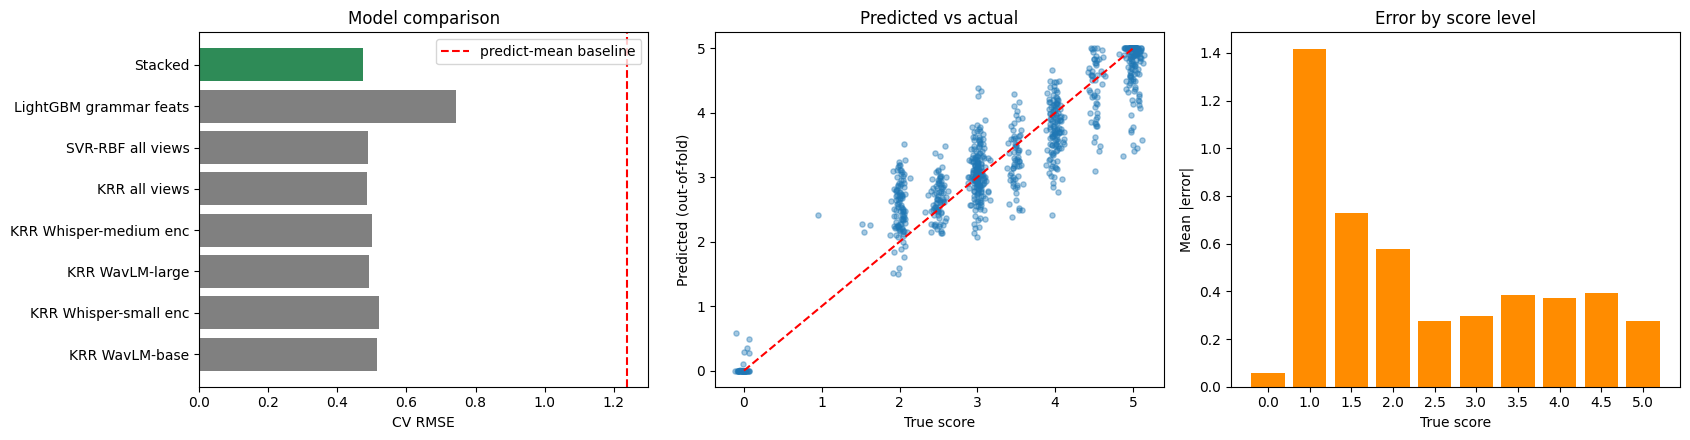

In [13]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
res = {n: rmse(y, oof[n]) for n in names}; res["Stacked"] = cv_rmse_stack
ax[0].barh(list(res), list(res.values()), color=["gray"] * len(names) + ["seagreen"])
ax[0].axvline(y.std(), color="red", ls="--", label="predict-mean baseline")
ax[0].set_xlabel("CV RMSE"); ax[0].set_title("Model comparison"); ax[0].legend()

jit = np.random.normal(0, 0.05, len(y))
ax[1].scatter(y + jit, stack_cv, alpha=0.4, s=14); ax[1].plot([0, 5], [0, 5], "r--")
ax[1].set_xlabel("True score"); ax[1].set_ylabel("Predicted (out-of-fold)"); ax[1].set_title("Predicted vs actual")

err = pd.DataFrame({"true": y, "abs_err": np.abs(y - stack_cv)}).groupby("true")["abs_err"].mean()
ax[2].bar(err.index.astype(str), err.values, color="darkorange")
ax[2].set_xlabel("True score"); ax[2].set_ylabel("Mean |error|"); ax[2].set_title("Error by score level")
plt.tight_layout(); plt.show()

## 9. Create submission

In [14]:
submission = pd.DataFrame({"filename": test_df["filename"].values, "label": test_stack})
assert len(submission) == len(test_df) and submission["label"].notna().all()
if list(sample_sub.columns) != list(submission.columns):
    print("WARNING: sample_submission columns are", list(sample_sub.columns), "- rename before submitting")
print("Prediction range: %.2f - %.2f | mean %.2f" % (submission["label"].min(), submission["label"].max(), submission["label"].mean()))
submission.to_csv(WORK / "submission.csv", index=False)
print("Saved:", WORK / "submission.csv")
submission.head()

Prediction range: 1.75 - 5.00 | mean 3.27
Saved: working/submission.csv


,filename,label
0,audio_128.wav,2.789039
1,audio_156.wav,4.418229
2,audio_19.wav,4.515015
3,audio_108.wav,2.211290
4,audio_206.wav,2.259329


## 10. Report

In [15]:
from IPython.display import Markdown, display
weights = ", ".join(f"{n}: {w:.2f}" for n, w in zip(names, stacker.coef_) if w > 0.005)
display(Markdown(f"""
### Approach
**Problem.** Regress a 0-5 grammar score from 45-60 s of speech (769 training clips, 216 test clips).

**Preprocessing.** Audio resampled to 16 kHz mono, capped at 60 s. Transcribed with Whisper (`{WHISPER_MODEL}`) with word timestamps and probabilities. Embedding features are z-scored without labels; missing values are handled natively by LightGBM.

**Pipeline.**
1. *Four audio views* (WavLM-base, Whisper-small encoder, WavLM-large, Whisper-medium encoder): per-layer mean+std pooling, converted to linear kernels; a fixed band of layers per view is used (no label-based layer picking).
2. *Base models:* kernel ridge per view (alpha by leave-one-out inside each training fold), kernel ridge and RBF-SVR on the averaged kernel of all views, LightGBM on 63 grammar/fluency features (LanguageTool, CoLA, GPT-2, Whisper confidence, pauses, text statistics).
3. *Stacker:* non-negative linear regression on out-of-fold predictions; output clipped to [0, 5]. Weights: {weights}.

**Evaluation.** 5-fold stratified CV repeated 3 times; OOF predictions feed the stacker, whose own CV estimate is reported.

| Metric | Value |
|---|---|
| **Training RMSE (in-sample)** | **{TRAIN_RMSE:.4f}** |
| Cross-validated RMSE (stacked) | {cv_rmse_stack:.4f} |
| CV Pearson | {cv_pearson:.4f} |
| CV R2 | {cv_r2:.4f} |
| Baseline (predict mean) RMSE | {y.std():.4f} |

**Interpretation.** Training RMSE is in-sample (the models have seen those labels, and the stacker is fitted on out-of-fold predictions), so it is only a sanity check; CV RMSE is the honest estimate. Audio embeddings carry most of the signal, the grammar features add complementary interpretable evidence. Errors are largest at extreme scores (few examples, noisy human ratings).

**Limitations.** The band of layers per view is chosen among 3 options by CV (tiny optimistic bias). Whisper partly auto-corrects mistakes. Next steps: fine-tune a speech model with augmentation, add transcript embeddings from a text encoder, or use the Whisper-large encoder.
"""))


### Approach
**Problem.** Regress a 0-5 grammar score from 45-60 s of speech (769 training clips, 216 test clips).

**Preprocessing.** Audio resampled to 16 kHz mono, capped at 60 s. Transcribed with Whisper (`small`) with word timestamps and probabilities. Embedding features are z-scored without labels; missing values are handled natively by LightGBM.

**Pipeline.**
1. *Four audio views* (WavLM-base, Whisper-small encoder, WavLM-large, Whisper-medium encoder): per-layer mean+std pooling, converted to linear kernels; a fixed band of layers per view is used (no label-based layer picking).
2. *Base models:* kernel ridge per view (alpha by leave-one-out inside each training fold), kernel ridge and RBF-SVR on the averaged kernel of all views, LightGBM on 63 grammar/fluency features (LanguageTool, CoLA, GPT-2, Whisper confidence, pauses, text statistics).
3. *Stacker:* non-negative linear regression on out-of-fold predictions; output clipped to [0, 5]. Weights: KRR WavLM-base: 0.02, KRR WavLM-large: 0.30, KRR Whisper-medium enc: 0.23, KRR all views: 0.05, SVR-RBF all views: 0.40, LightGBM grammar feats: 0.08.

**Evaluation.** 5-fold stratified CV repeated 3 times; OOF predictions feed the stacker, whose own CV estimate is reported.

| Metric | Value |
|---|---|
| **Training RMSE (in-sample)** | **0.1123** |
| Cross-validated RMSE (stacked) | 0.4745 |
| CV Pearson | 0.9238 |
| CV R2 | 0.8531 |
| Baseline (predict mean) RMSE | 1.2382 |

**Interpretation.** Training RMSE is in-sample (the models have seen those labels, and the stacker is fitted on out-of-fold predictions), so it is only a sanity check; CV RMSE is the honest estimate. Audio embeddings carry most of the signal, the grammar features add complementary interpretable evidence. Errors are largest at extreme scores (few examples, noisy human ratings).

**Limitations.** The band of layers per view is chosen among 3 options by CV (tiny optimistic bias). Whisper partly auto-corrects mistakes. Next steps: fine-tune a speech model with augmentation, add transcript embeddings from a text encoder, or use the Whisper-large encoder.
